In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.linear_model import RidgeClassifier, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score
from sklearn.linear_model import RidgeClassifierCV

In [2]:
#load EPA AQS data
aqs= "/Users/gabrielagarcia/Desktop/Fall 2026/Geol 415/hw3/LA_AQS_2023.csv"
ds_aqs= pd.read_csv(aqs)

In [3]:
#store O3 and NO2 and PM2.5 data into files
O3 = ds_aqs[ds_aqs['Parameter Name'] == 'Ozone'].copy()
NO2 = ds_aqs[ds_aqs['Parameter Name'] == 'Nitrogen dioxide (NO2)'].copy()
PM= ds_aqs[ds_aqs['Parameter Name']== 'PM2.5 - Local Conditions'].copy()
#merge NO2 and O3 data 
O3["Date (Local)"] = pd.to_datetime(O3["Date (Local)"])
NO2["Date (Local)"] = pd.to_datetime(NO2["Date (Local)"])
PM["Date (Local)"]= pd.to_datetime(PM["Date (Local)"])
df_all = O3.merge(NO2, on=["Date (Local)"]).merge(PM, on=["Date (Local)"])
df_all.columns

Index(['State Code_x', 'County Code_x', 'Site Number_x', 'Parameter Code_x',
       'POC_x', 'Latitude_x', 'Longitude_x', 'Datum_x', 'Parameter Name_x',
       'Duration Description_x', 'Pollutant Standard_x', 'Date (Local)',
       'Year_x', 'Day In Year (Local)_x', 'Units of Measure_x',
       'Exceptional Data Type_x', 'Nonreg Observation Count_x',
       'Observation Count_x', 'Observation Percent_x',
       'Nonreg Arithmetic Mean_x', 'Arithmetic Mean_x',
       'Nonreg First Maximum Value_x', 'First Maximum Value_x',
       'First Maximum Hour_x', 'AQI_x', 'Daily Criteria Indicator_x',
       'Tribe Name_x', 'State Name_x', 'County Name_x', 'City Name_x',
       'Local Site Name_x', 'Address_x', 'MSA or CBSA Name_x', 'Data Source_x',
       'State Code_y', 'County Code_y', 'Site Number_y', 'Parameter Code_y',
       'POC_y', 'Latitude_y', 'Longitude_y', 'Datum_y', 'Parameter Name_y',
       'Duration Description_y', 'Pollutant Standard_y', 'Year_y',
       'Day In Year (Local)_y'

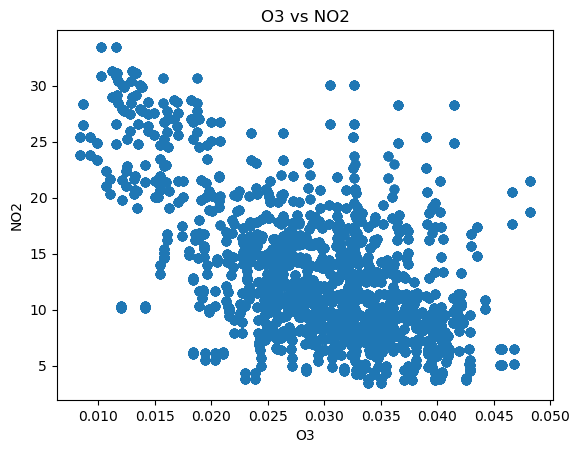

In [4]:
#Make scatter plot of all O3 and NO2 data
plt.scatter(df_all["Arithmetic Mean_x"], df_all["Arithmetic Mean_y"])

plt.xlabel("O3")
plt.ylabel("NO2")
plt.title("O3 vs NO2")
plt.show()

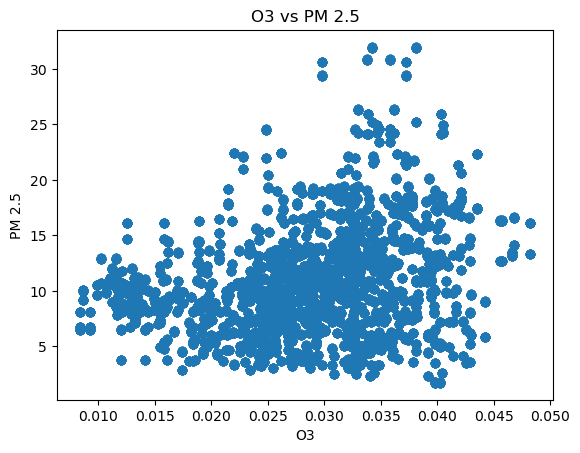

In [5]:
#Make scatter plot of O3 vs PM2.5
plt.scatter(df_all["Arithmetic Mean_x"], df_all["Arithmetic Mean"])
plt.xlabel("O3")
plt.ylabel("PM 2.5")
plt.title("O3 vs PM 2.5")
plt.show()

In [6]:
#rename O3 and NO2 columns
df_all = df_all.rename(columns={'Arithmetic Mean_x': 'O3'})
df_all = df_all.rename(columns={'Arithmetic Mean_y': 'NO2'})
df_all = df_all.rename(columns={'Arithmetic Mean': 'PM'})

In [7]:
#filter out data by season
def get_season(day):
    # Summer: June, July, August
    if 152 <= day <= 243:
        return 'summer'
    # Winter: December, January, February
    elif day >= 335 or day <= 59:
        return 'winter'
    else:
        return 'other' # For Spring and Autumn

In [8]:
#add column to data set with season
df_all['season'] = df_all['Day In Year (Local)_x'].apply(get_season)

In [9]:
#filter out unwanted seasons and create a binary with just winter and summer as options
binary_df = df_all[df_all['season'].isin(['summer', 'winter'])].copy()
binary_df.columns

Index(['State Code_x', 'County Code_x', 'Site Number_x', 'Parameter Code_x',
       'POC_x', 'Latitude_x', 'Longitude_x', 'Datum_x', 'Parameter Name_x',
       'Duration Description_x',
       ...
       'Daily Criteria Indicator', 'Tribe Name', 'State Name', 'County Name',
       'City Name', 'Local Site Name', 'Address', 'MSA or CBSA Name',
       'Data Source', 'season'],
      dtype='object', length=101)

In [10]:
#assign x to columns with NO2 and O3 data and y to season
x = binary_df[['O3', 'NO2','PM']] 
y = binary_df['season']

In [11]:
#split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2)

In [12]:
#scale x data since it values are in different units
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
#assign alpha value
clf = RidgeClassifier(alpha=1.0)

#train model 
clf.fit(X_train_scaled, y_train)
#generate prediction from test data
y_pred = clf.predict(X_test_scaled)
# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 87.97%

Classification Report:
              precision    recall  f1-score   support

      summer       0.85      0.97      0.91       756
      winter       0.94      0.75      0.83       507

    accuracy                           0.88      1263
   macro avg       0.90      0.86      0.87      1263
weighted avg       0.89      0.88      0.88      1263



In [14]:
#  Ridge classifier classifies one season as -1 and the other as 1 and treats them as a regression task by fitting a straight
#line through the values.

In [15]:
#generate alpha values to test
alpha_candidates = np.logspace(-3, 3, 7)
clf_cv = RidgeClassifierCV(alphas=alpha_candidates)
#train again
clf_cv.fit(X_train_scaled, y_train)
#find optimal value
optimal_alpha = clf_cv.alpha_
optimal_alpha

np.float64(10.0)

In [16]:
validation_accuracies = []

for alpha in alpha_candidates:
    clf = RidgeClassifier(alpha=alpha)
    clf.fit(X_train_scaled, y_train)

    y_val_pred = clf.predict(X_test_scaled)
    validation_accuracies.append(
        accuracy_score(y_test, y_pred)
    )

validation_optimal_alpha = alpha_candidates[
    np.argmax(validation_accuracies)
]

print("Validation optimal alpha:", validation_optimal_alpha)

Validation optimal alpha: 0.001


In [17]:
#3. Optimal penalty was 10.
#4. Optimal penalty is 0.001 for test data.

In [18]:
y_pred_test = clf_cv.predict(X_test_scaled)

# Calculate accuracy and convert it to error rate
test_accuracy = accuracy_score(y_test, y_pred_test)
test_error = 1.0 - test_accuracy

print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Error Rate: {test_error * 100:.2f}%")

Final Test Accuracy: 87.97%
Error Rate: 12.03%


In [19]:
#5 Using the test_accuracy and test_error functions from sklearn, the error rate is 14%.

In [20]:
#Redo train/validation splits and rerun ridge classifier
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    x, y, test_size=0.2)
#scale x data since it values are in different units
scaler = StandardScaler()
X_train_scaled_2 = scaler.fit_transform(X_train_2)
X_test_scaled_2 = scaler.transform(X_test_2)
#assign alpha value
clf_2 = RidgeClassifier(alpha=1.0)

#train model 
clf_2.fit(X_train_scaled_2, y_train_2)
#generate prediction from test data
y_pred_2 = clf_2.predict(X_test_scaled_2)
# Evaluate performance
accuracy_2 = accuracy_score(y_test_2, y_pred_2)
print(f"Model Accuracy: {accuracy_2 * 100:.2f}%\n")
test_error_2 = 1.0 - accuracy_2
print(f"Error Rate: {test_error_2 * 100:.2f}%")

print("Classification Report:")
print(classification_report(y_test_2, y_pred_2))
#generate alpha values to test
clf_cv_2 = RidgeClassifierCV(alphas=alpha_candidates)
#train again
clf_cv_2.fit(X_train_scaled_2, y_train_2)
#find optimal value
optimal_alpha_2 = clf_cv_2.alpha_
optimal_alpha_2

Model Accuracy: 87.41%

Error Rate: 12.59%
Classification Report:
              precision    recall  f1-score   support

      summer       0.85      0.96      0.90       768
      winter       0.92      0.75      0.82       495

    accuracy                           0.87      1263
   macro avg       0.89      0.85      0.86      1263
weighted avg       0.88      0.87      0.87      1263



np.float64(10.0)

In [21]:
# When I reran the code with a new set of test and train data, I get the same optimal alpha value and slightly different model accuracy 
#and slightly different values in classification report.

In [22]:
#run logistic regression on second set of data
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled_2, y_train_2)

log_pred = log_reg.predict(X_test_scaled_2)
log_accuracy = accuracy_score(y_test_2, log_pred)

print(f"\nLogistic regression accuracy: {log_accuracy * 100:.2f}%")
print(f"Logistic regression error rate: {(1 - log_accuracy) * 100:.2f}%")


Logistic regression accuracy: 88.44%
Logistic regression error rate: 11.56%


In [23]:
#7.  Ridge classifier accuracy was 87.41% using second set of training and test data.  Logistic accuracy was slighlty higher at 88.44%.  
#The error rate for the ridge classifier was slightly higher (12.59%) than the error rate for the logistic regression (11.56%).  So The linear 
#regression model performed slightly better.